In [1]:
#!pip install --user antspyx

In [2]:
import sys
import os
import os.path as op
import glob
import nibabel as nib

# Make utils.py (lab helpers) importable
notebook_dir = os.path.abspath("")
sys.path.append(os.path.abspath(os.path.join(notebook_dir, '..')))
sys.path.append('.')
from utils import loadFSL, FSLeyesServer

# Load FSL in Neurodesk
import module as lmod
await lmod.purge(force=True)
await lmod.load('fsl/6.0.7.18')
loadFSL()

from fsl.wrappers import fast, flirt

In [3]:
from nilearn import plotting
fig_dir = op.abspath("outputs/figures")
os.makedirs(fig_dir, exist_ok=True)

In [4]:
%gui wx


(ipykernel_launcher.py:3692): dbind-WARNING **: 13:09:10.141: Couldn't connect to accessibility bus: Failed to connect to socket /run/user/203553799/at-spi/bus_100: No such file or directory


In [5]:
################
# Start FSLeyes
################
fsleyesDisplay = FSLeyesServer()
fsleyesDisplay.show()

13:09:18: Debug: Adding duplicate image handler for 'Windows bitmap file'
13:09:18: Debug: Adding duplicate animation handler for '1' type
13:09:18: Debug: Adding duplicate animation handler for '2' type
13:09:18: Debug: Adding duplicate image handler for 'Windows bitmap file'
13:09:18: Debug: Adding duplicate animation handler for '1' type
13:09:18: Debug: Adding duplicate animation handler for '2' type

(ipykernel_launcher.py:3692): Gtk-CRITICAL **: 13:09:18.438: gtk_window_resize: assertion 'width > 0' failed

(ipykernel_launcher.py:3692): Gtk-CRITICAL **: 13:09:20.187: gtk_window_resize: assertion 'width > 0' failed


In [6]:
t1_path = op.abspath("miniproject_2026_final/T1/T1w.nii.gz")
print(t1_path, op.isfile(t1_path)) 

/home/jovyan/miniproject_2026_final/T1/T1w.nii.gz True


In [7]:
# Visual check of the raw T1w
fsleyesDisplay.resetOverlays()
fsleyesDisplay.load(t1_path)

## 1.1 Skull stripping

In [6]:
def get_skull_stripped_anatomical(anatomical_path, output_dir, robust=True):
    # -R: robust center estimation, avoids leaving neck tissue
    os.makedirs(output_dir, exist_ok=True)
    betted_brain_path = op.join(output_dir, 'T1w')
    os.system('bet {} {} -m {}'.format(anatomical_path, betted_brain_path, '-R' if robust else ''))
    print("Done with BET.")

# paths
anatomical_path = op.abspath("miniproject_2026_final/T1/T1w.nii.gz") #path to the T1w image
output_dir = op.abspath("outputs/anat") #where the results are saved

get_skull_stripped_anatomical(anatomical_path, output_dir)

resulting_mask_path = op.join(output_dir, 'T1w_mask')

Done with BET.


In [9]:
fsleyesDisplay.load(resulting_mask_path)

In [8]:
def apply_python_mask_approach(img_path, mask_path, masked_img_path):

    # Load both the T1 and the mask from disk
    img = nib.load(img_path)
    mask = nib.load(mask_path)
    
    # Load the data from both above images as numpy arrays
    img_data = img.get_fdata()
    mask_data = mask.get_fdata()
    
    # In all positions OUTSIDE the mask (equal to 0), throw away the image
    img_data[mask_data == 0] = 0
    
    # Save the image to disk, by creating a new Nifti image and then writing it out
    img_out = nib.Nifti1Image(img_data,img.affine, img.header)
    nib.save(img_out, masked_img_path)

betted_brain_path = op.join(output_dir, 'T1w_masked.nii.gz') 
resulting_mask_path = op.join(output_dir, 'T1w_mask.nii.gz') # The mask to use

apply_python_mask_approach(anatomical_path, resulting_mask_path, betted_brain_path)

In [11]:
fsleyesDisplay.resetOverlays()
fsleyesDisplay.load(betted_brain_path)

## 1.2 Tissue segmentation

In [9]:
# FAST is applied to the skull-stripped brain: skull and scalp would otherwise be classified as tissue.
fast_target = betted_brain_path   

[os.remove(f) for f in glob.glob(op.join(output_dir, '*fast*'))] # Just to clean the directory in between runs of the cell
segmentation_path = op.join(output_dir, 'T1w_fast')
# n_classes=3 -> CSF, grey matter, white matter (pve_0, pve_1, pve_2)
fast(imgs=[fast_target], out=segmentation_path, n_classes=3)

{}

In [14]:
fsleyesDisplay.resetOverlays()
fsleyesDisplay.load(betted_brain_path)
fsleyesDisplay.load(glob.glob(op.join(output_dir, '*pve_0*'))[0])
fsleyesDisplay.load(glob.glob(op.join(output_dir, '*pve_1*'))[0])
fsleyesDisplay.load(glob.glob(op.join(output_dir, '*pve_2*'))[0])
fsleyesDisplay.displayCtx.getOpts(fsleyesDisplay.overlayList[1]).cmap = 'Red'
fsleyesDisplay.displayCtx.getOpts(fsleyesDisplay.overlayList[2]).cmap = 'Green'
fsleyesDisplay.displayCtx.getOpts(fsleyesDisplay.overlayList[3]).cmap = 'Blue'

## 1.3 Registration

In [10]:
#from fsl.wrappers import flirt

subject_anatomical = betted_brain_path
mni_template = op.expandvars(op.join('$FSLDIR', 'data', 'standard', 'MNI152_T1_1mm_brain'))

  # Source = subject T1w (moved), reference = MNI152 1mm brain template (fixed).
  # We map the subject to the template so results can be compared in standard space.

source = subject_anatomical 
reference = mni_template
result = op.join(output_dir, 'T1w_mni')
flirt(source, reference, out=result)


Final result: 
1.078909 -0.015680 0.008415 -6.129257 
0.023288 1.123096 -0.006228 -16.343431 
-0.020852 -0.011642 1.191129 -8.805752 
0.000000 0.000000 0.000000 1.000000 



{}

Flirt vizualisation : 

In [17]:
fsleyesDisplay.resetOverlays()
fsleyesDisplay.load(reference) 
fsleyesDisplay.load(result)

Choosing a cost:

In [18]:
# Same modality (T1w -> T1w template): within-modality intensity-based costs (leastsq, normcorr)
costs = [ 'leastsq', 'normcorr' ] 

for c in costs:
    flirt(source, reference, out=result + '_' + c, cost=c)


Final result: 
1.165288 -0.025935 0.016915 -13.515540 
0.029091 1.222016 -0.028761 -25.740137 
-0.015456 -0.024104 1.452098 -29.121278 
0.000000 0.000000 0.000000 1.000000 


Final result: 
1.070191 -0.015001 0.009304 -5.499236 
0.023592 1.115159 -0.005633 -15.657697 
-0.020778 -0.010821 1.178435 -7.862419 
0.000000 0.000000 0.000000 1.000000 



In [19]:
# Before/after: compare the subject T1w and the MNI template overlay
for c in costs:
    fsleyesDisplay.load(result + '_' + c)

In [11]:
final_cost = 'normcorr'   # the one we keep
mat_path = op.join(output_dir, 'T1w_to_MNI.mat')
flirt(source, reference, out=op.join(output_dir, 'T1w_mni_final'),
      cost=final_cost, omat=mat_path)

{}

In [12]:
for name, interp in [('seg', 'nearestneighbour'),
                     ('pve_0', 'trilinear'), ('pve_1', 'trilinear'), ('pve_2', 'trilinear')]:
    flirt(op.join(output_dir, f'T1w_fast_{name}.nii.gz'), reference,
          out=op.join(output_dir, f'T1w_fast_{name}_mni'),
          applyxfm=True, init=mat_path, interp=interp)

In [23]:
# List outputs to check all files were created
!ls -lh {output_dir}

total 81M
-rw-rw-r-- 1 jovyan jovyan  13M Nov  3 13:03 T1w.nii.gz
-rw-rw-r-- 1 jovyan jovyan 871K Nov  3 13:11 T1w_fast_mixeltype.nii.gz
-rw-rw-r-- 1 jovyan jovyan 1.7M Nov  3 13:11 T1w_fast_pve_0.nii.gz
-rw-rw-r-- 1 jovyan jovyan 4.4M Nov  3 13:19 T1w_fast_pve_0_mni.nii.gz
-rw-rw-r-- 1 jovyan jovyan 2.9M Nov  3 13:11 T1w_fast_pve_1.nii.gz
-rw-rw-r-- 1 jovyan jovyan 6.1M Nov  3 13:19 T1w_fast_pve_1_mni.nii.gz
-rw-rw-r-- 1 jovyan jovyan 1.6M Nov  3 13:11 T1w_fast_pve_2.nii.gz
-rw-rw-r-- 1 jovyan jovyan 4.1M Nov  3 13:20 T1w_fast_pve_2_mni.nii.gz
-rw-rw-r-- 1 jovyan jovyan 759K Nov  3 13:11 T1w_fast_pveseg.nii.gz
-rw-rw-r-- 1 jovyan jovyan 755K Nov  3 13:11 T1w_fast_seg.nii.gz
-rw-rw-r-- 1 jovyan jovyan 404K Nov  3 13:19 T1w_fast_seg_mni.nii.gz
-rw-rw-r-- 1 jovyan jovyan 182K Nov  3 13:03 T1w_mask.nii.gz
-rw-rw-r-- 1 jovyan jovyan  14M Nov  3 13:04 T1w_masked.nii.gz
-rw-rw-r-- 1 jovyan jovyan 7.1M Nov  3 13:13 T1w_mni.nii.gz
-rw-rw-r-- 1 jovyan jovyan 6.9M Nov  3 13:19 T1w_mni_final.nii.

## 2. Functional preprocessing

### a) Motion correction

The first step to do before correcting motion is to inspect our data on fsleye to see if there is any abnormal volume that we could remove

In [13]:
import os, os.path as op
import nibabel as nib
import matplotlib.pyplot as plt

project_root = op.abspath("")
data_root     = op.join(project_root, "miniproject_2026_final")
fMRI_raw     = op.join(data_root, "fMRI")
fMRI_lang_raw = op.join(fMRI_raw, "tfMRI_LANGUAGE_LR")
func_file    = op.join(fMRI_lang_raw, "tfMRI_LANGUAGE_LR.nii.gz")   

4D visualisation : 

In [14]:
fsleyesDisplay.resetOverlays()
fsleyesDisplay.load(func_file)

We can also quantify the abnormal volumes by computing and ploting the mean intensity per volume : 

(91, 109, 91, 316)


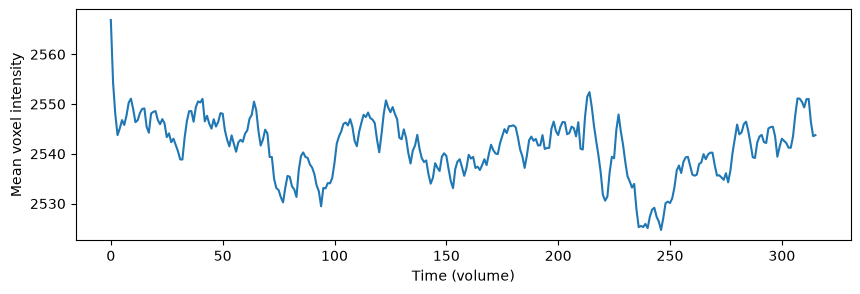

In [15]:
img  = nib.load(func_file)
data = img.get_fdata()
print(img.shape)                      # (x, y, z, n_volumes)

mean_per_vol = data.mean(axis=(0, 1, 2))

plt.figure(figsize=(10, 3))
plt.plot(mean_per_vol)
plt.xlabel('Time (volume)')
plt.ylabel('Mean voxel intensity')
plt.show()

If we look at the plot we can clearly see that the first ~ 3 volumes have a high contrast that quickly decayed to some baseline. This is caused by the scanner's field settling. Around volumes 210-250, the mean intensity shows a peak followed by a drop, we will compare this with the FD plot to see whether it coincides with head motion.
In the next step, we remove the first 10 volumes that are impacted by field stabilisation. 


In [16]:
from fsl.wrappers import fslroi, mcflirt

n_discard = 10        # volumes we remove
n_vols    = img.shape[3]

out_func = op.join(project_root, "outputs", "func")
os.makedirs(out_func, exist_ok=True)

trimmed = op.join(out_func, "tfMRI_LANGUAGE_LR_trim")          
moco    = op.join(out_func, "tfMRI_LANGUAGE_LR_trim_moco")


fslroi(func_file, trimmed, n_discard, n_vols - n_discard) #trimmedcorrespond to the data without the first 10 volumes

{}

Finally, we can run MCFLIRT to correct motion

In [17]:
mcflirt(infile=trimmed, o=moco, plots=True, mats=True, dof=6, report=True)

Processed data will be saved as /home/jovyan/outputs/func/tfMRI_LANGUAGE_LR_trim_moco

McFLIRT v 2.0 - FMRI motion correction

Reading time series... 
first iteration - 8mm scaling, set tolerance
Rescaling reference volume [153] to 8 mm pixels
Registering volumes ... [154][155][156][157][158][159][160][161][162][163][164][165][166][167][168][169][170][171][172][173][174][175][176][177][178][179][180][181][182][183][184][185][186][187][188][189][190][191][192][193][194][195][196][197][198][199][200][201][202][203][204][205][206][207][208][209][210][211][212][213][214][215][216][217][218][219][220][221][222][223][224][225][226][227][228][229][230][231][232][233][234][235][236][237][238][239][240][241][242][243][244][245][246][247][248][249][250][251][252][253][254][255][256][257][258][259][260][261][262][263][264][265][266][267][268][269][270][271][272][273][274][275][276][277][278][279][280][281][282][283][284][285][286][287][288][289][290][291][292][293][294][295][296][297][298][299][3

refnum = 153
Original_refvol = -1


Registering volumes ... [154][155][156][157][158][159][160][161][162][163][164][165][166][167][168][169][170][171][172][173][174][175][176][177][178][179][180][181][182][183][184][185][186][187][188][189][190][191][192][193][194][195][196][197][198][199][200][201][202][203][204][205][206][207][208][209][210][211][212][213][214][215][216][217][218][219][220][221][222][223][224][225][226][227][228][229][230][231][232][233][234][235][236][237][238][239][240][241][242][243][244][245][246][247][248][249][250][251][252][253][254][255][256][257][258][259][260][261][262][263][264][265][266][267][268][269][270][271][272][273][274][275][276][277][278][279][280][281][282][283][284][285][286][287][288][289][290][291][292][293][294][295][296][297][298][299][300][301][302][303][304][305][152][151][150][149][148][147][146][145][144][143][142][141][140][139][138][137][136][135][134][133][132][131][130][129][128][127][126][125][124][123][122][121][120][119][118][117][116][115][114][113][112][111][110][

{}

Framewise displacement :

Framewise displacement was computed from the six rigid-body motion parameters estimated by MCFLIRT on the trimmed data.

In [18]:
import os, os.path as op
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

motion_params_path = op.join(project_root, "outputs", "func", "tfMRI_LANGUAGE_LR_trim_moco.par") 
print(op.exists(motion_params_path))   

mot_params = pd.read_csv(motion_params_path, sep=r"\s+", header=None,
                         names=['Rotation x', 'Rotation y', 'Rotation z',
                                'Translation x', 'Translation y', 'Translation z'])

# computing Framewise Diisplacement
def compute_FD_power(mot_params):
    framewise_diff = mot_params.diff().iloc[1:]          

    rot_params = framewise_diff[['Rotation x', 'Rotation y', 'Rotation z']]
    converted_rots = rot_params * 50                     

    trans_params = framewise_diff[['Translation x', 'Translation y', 'Translation z']]

    return converted_rots.abs().sum(axis=1) + trans_params.abs().sum(axis=1)

fd = compute_FD_power(mot_params).to_numpy()

# Treshold : Q3 + 1.5 * IQR
q1, q3 = np.quantile(fd, [0.25, 0.75])
threshold = q3 + 1.5 * (q3 - q1)


True


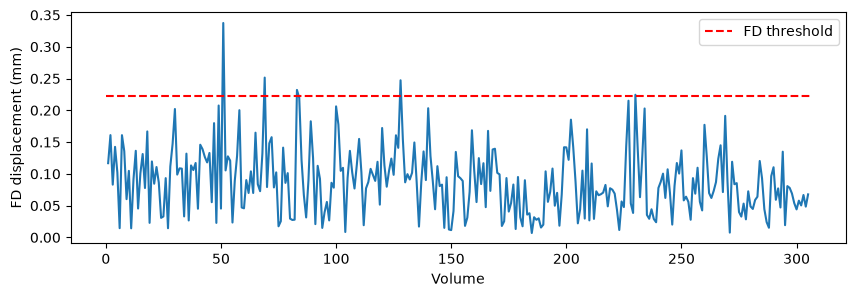

FD Treshold : 0.222 mm
Indices of frames above threshold: [51, 69, 83, 128, 230]


In [19]:
plt.figure(figsize=(10, 3))
plt.plot(range(1, fd.size + 1), fd)
plt.hlines(threshold, 0, fd.size + 1, colors='red', linestyles='dashed', label='FD threshold')
plt.xlabel('Volume')
plt.ylabel('FD displacement (mm)')
plt.legend()

# Figure
fig_dir = op.join(project_root, "outputs", "figures")
os.makedirs(fig_dir, exist_ok=True)
plt.savefig(op.join(fig_dir, "fd_tfMRI_LANGUAGE_LR.png"), dpi=150, bbox_inches="tight")
plt.show()

# Volumes above treshold
bad_vols = (np.where(fd > threshold)[0] + 1).tolist()
print(f"FD Treshold : {threshold:.3f} mm")
print(f"Indices of frames above threshold: {bad_vols}")

**Comments :** 

The framewise displacement (FD) remains low throughout the run: most volumes show an FD below the threshold (0.222 mm), with a maximum of 0.34 mm at volume 51. Using an outlier criterion (Q3 + 1.5 × IQR = 0.222 mm), only the following five volumes : **51, 69, 83, 128 and 230** exceed the threshold. These are isolated single-volume spikes rather than sustained periods of motion, which suggests that the participant moved very little. Also when we displayed the volumes on fsleye we could not see any significant motion for those volumes (by eye) compared to the previous/next one.

Since this threshold is data-driven, it flags relative outliers even when absolute motion is small. The signal changes observed in the mean intensity around volumes 210-250 of the raw series do not coincide with a clear FD peak, so they are probably not mainly driven by head motion, although FD only captures volume-to-volume displacement.

Motion correction realigns the volumes but cannot remove the residual, non-linear effects of motion on the signal (e.g. through changes in the magnetic field). These can be reduced later by including the six motion parameters, and if needed one regressor per flagged volume, as nuisance regressors in the GLM.

Motion between volume 51 and 50 :

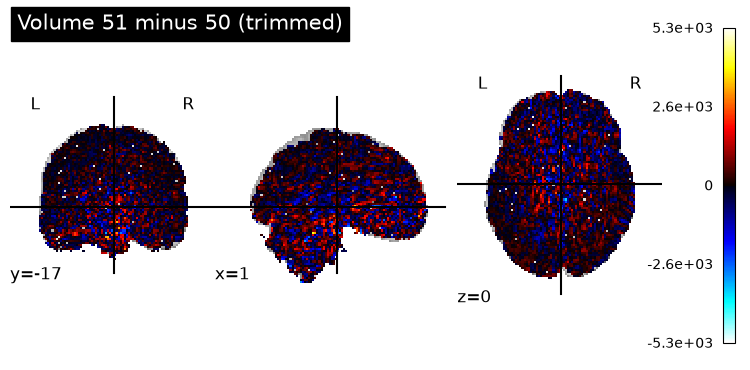

In [10]:
from nilearn import plotting, image
import matplotlib.pyplot as plt

vol = 51
trim_func_base = op.join(project_root, "outputs", "func", "tfMRI_LANGUAGE_LR_trim")
moco_func_base = op.join(project_root, "outputs", "func", "tfMRI_LANGUAGE_LR_trim_moco")
trim_vol = image.index_img(trim_func_base + ".nii.gz", vol)  
moco_vol = image.index_img(moco_func_base + ".nii.gz", vol)      
ref_vol  = image.index_img(moco_func_base + ".nii.gz", vol - 1)  

diff = image.math_img("a - b", a=trim_vol, b=image.index_img(trim_func_base + ".nii.gz", vol - 1))
plotting.plot_stat_map(diff, title=f"Volume {vol} minus {vol-1} (trimmed)")

The figure shows the voxel-wise difference between volume 51 and volume 50 (before motion correction)

### b) Gaussian smoothing

FWHM choice : 2 to 3 times the voxel's size. Given the voxel's size of 2, we choose FWHM = 6.

In [32]:
img = nib.load(moco_func_base + ".nii.gz")
print("Voxel size (mm):", img.header.get_zooms()[:3])
print("TR (s):", img.header.get_zooms()[3])
print("Shape:", img.shape)

Voxel size (mm): (np.float32(2.0), np.float32(2.0), np.float32(2.0))
TR (s): 0.72
Shape: (91, 109, 91, 306)


In [20]:
import subprocess


trim_func_base = op.join(project_root, "outputs", "func", "tfMRI_LANGUAGE_LR_trim")
moco_func_base = op.join(project_root, "outputs", "func", "tfMRI_LANGUAGE_LR_trim_moco")

fwhm_mm = 6
sigma = fwhm_mm / 2.3548
smoothed_func_base = f"{moco_func_base}_smoothed-{fwhm_mm}mm"

subprocess.run(["fslmaths", moco_func_base, "-s", str(sigma), smoothed_func_base], check=True)

CompletedProcess(args=['fslmaths', '/home/jovyan/outputs/func/tfMRI_LANGUAGE_LR_trim_moco', '-s', '2.547987090198743', '/home/jovyan/outputs/func/tfMRI_LANGUAGE_LR_trim_moco_smoothed-6mm'], returncode=0)

Visualisation :

In [22]:
from nilearn import plotting, image

vol = 100
fig_dir = op.join(project_root, "outputs", "figures")
os.makedirs(fig_dir, exist_ok=True)

before_file   = moco_func_base     + ".nii.gz"
smoothed_file = smoothed_func_base + ".nii.gz"

# Extracting the same volume before and after smoothing
before_vol   = op.join(fig_dir, f"tmp_before_vol{vol}.nii.gz")
smoothed_vol = op.join(fig_dir, f"tmp_after_vol{vol}.nii.gz")
image.index_img(before_file,   vol).to_filename(before_vol)
image.index_img(smoothed_file, vol).to_filename(smoothed_vol)

# View in FSLeyes 
fsleyesDisplay.resetOverlays()
fsleyesDisplay.load(before_vol)
fsleyesDisplay.load(smoothed_vol)

### c) Validate the alignment between anatomical and functional data

In [23]:
import os, os.path as op
import numpy as np
import nibabel as nib
from nilearn import plotting, image

# Files
epi_path = op.join(project_root, "outputs", "func", "tfMRI_LANGUAGE_LR_trim_moco.nii.gz")   # motion-corrected fMRI
print(os.listdir(op.join(project_root, "outputs", "anat")))     # find your T1 registered to MNI
t1_mni_path = op.join(project_root, "outputs", "anat", "T1w_mni_final.nii.gz")              # <- fill in

# Checking the file location
epi_img, t1_img = nib.load(epi_path), nib.load(t1_mni_path)
print("fMRI:", epi_img.shape[:3], epi_img.header.get_zooms()[:3])
print("T1  :", t1_img.shape[:3], t1_img.header.get_zooms()[:3])
print("Same affine:", np.allclose(epi_img.affine, t1_img.affine, atol=1e-3))

['T1w_mni.nii.gz', 'T1w_fast_pve_0_mni.nii.gz', 'T1w_fast_mixeltype.nii.gz', 'T1w_mni_final.nii.gz', 'T1w_fast_pve_0.nii.gz', 'T1w.nii.gz', 'T1w_fast_pve_2_mni.nii.gz', 'T1w_fast_seg_mni.nii.gz', 'T1w_masked.nii.gz', 'T1w_fast_pve_1_mni.nii.gz', 'T1w_fast_pveseg.nii.gz', 'T1w_to_MNI.mat', 'T1w_fast_pve_2.nii.gz', 'T1w_mask.nii.gz', 'T1w_fast_pve_1.nii.gz', 'T1w_fast_seg.nii.gz']
fMRI: (91, 109, 91) (np.float32(2.0), np.float32(2.0), np.float32(2.0))
T1  : (182, 218, 182) (np.float32(1.0), np.float32(1.0), np.float32(1.0))
Same affine: False


<Figure size 640x480 with 0 Axes>

<Figure size 640x480 with 0 Axes>

Visualisation :

In [24]:
vol = 100
epi_vol_file = op.join(fig_dir, f"tmp_epi_vol{vol}.nii.gz")
image.index_img(epi_img, vol).to_filename(epi_vol_file)

# View in FSLeyes
fsleyesDisplay.resetOverlays()
fsleyesDisplay.load(epi_vol_file)
fsleyesDisplay.load(t1_mni_path) 